Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


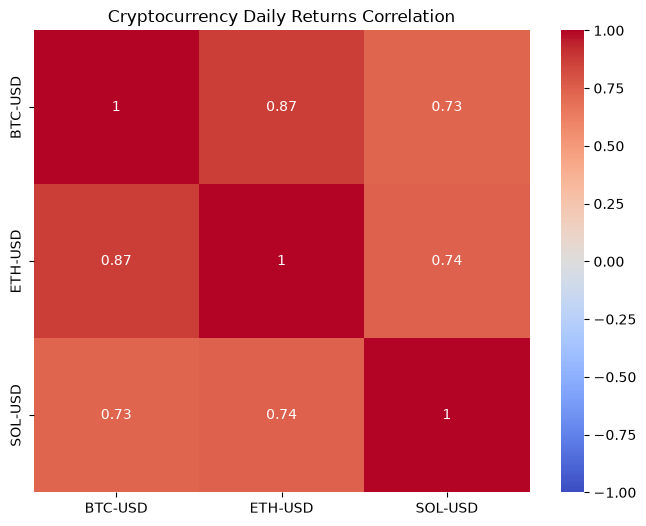

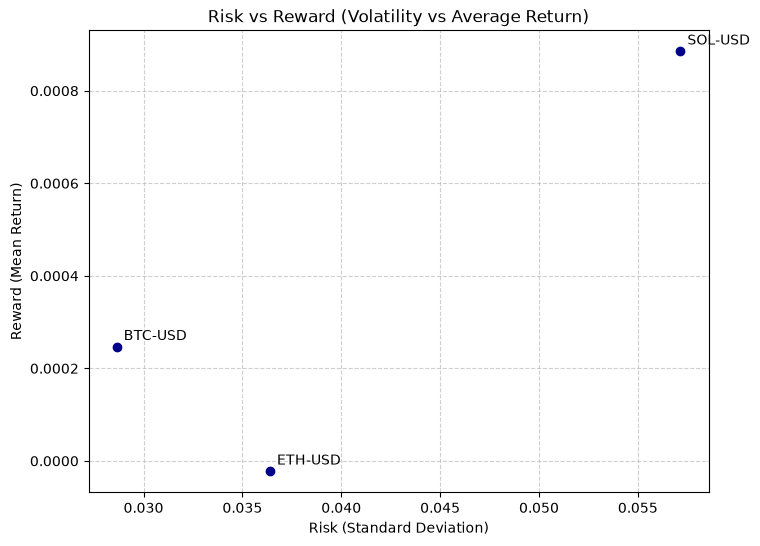

In [1]:
%pip install numpy
%pip install matplotlib
%pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the cleaned data
df_cleaned = pd.read_csv('../data/cleaned_crypto_prices.csv', index_col='Date', parse_dates=True)

# 2. Calculate daily returns
returns = df_cleaned[['BTC-USD', 'ETH-USD', 'SOL-USD']].pct_change().dropna()

# --- CHART 1: Correlation Heatmap ---
plt.figure(figsize=(8, 6))
sns.heatmap(returns.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Cryptocurrency Daily Returns Correlation")
plt.show()

# --- CHART 2: Risk vs. Reward (FIXED) ---
plt.figure(figsize=(8, 6))

# Plot the dots
plt.scatter(returns.std(), returns.mean(), color='darkblue')

# Add labels to the dots using the column names directly!
for coin in returns.columns:
    # Instead of [i], we use [coin] to look up the exact value for BTC, ETH, etc.
    x_value = returns.std()[coin] 
    y_value = returns.mean()[coin]
    
    plt.annotate(coin, (x_value, y_value), xytext=(5,5), textcoords='offset points')

plt.title("Risk vs Reward (Volatility vs Average Return)")
plt.xlabel("Risk (Standard Deviation)")
plt.ylabel("Reward (Mean Return)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [9]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import yfinance as yf
import os

# 1. Load the cleaned data for the line chart
df_cleaned = pd.read_csv('../data/cleaned_crypto_prices.csv', index_col='Date', parse_dates=True)

# --- INTERACTIVE CHART 1: Line Chart ---
fig1 = px.line(df_cleaned, 
                x=df_cleaned.index, 
                y=['BTC-USD', 'ETH-USD', 'SOL-USD'],
                title='Live Cryptocurrency Prices with Interactive Zoom')

fig1.update_xaxes(rangeslider_visible=True) 

# GUARANTEED DISPLAY METHOD: Save to HTML and open in browser
fig1.write_html("line_chart.html", auto_open=True)
print("Line chart opened in your web browser!")


# --- INTERACTIVE CHART 2: Candlestick Chart ---
# FIX: Use yf.Ticker().history() instead of yf.download() to prevent MultiIndex errors
btc_ticker = yf.Ticker('BTC-USD')
btc_full = btc_ticker.history(period='6mo')

fig2 = go.Figure(data=[go.Candlestick(x=btc_full.index,
                open=btc_full['Open'],
                high=btc_full['High'],
                low=btc_full['Low'],
                close=btc_full['Close'])])

fig2.update_layout(title='Bitcoin 6-Month Candlestick Chart', yaxis_title='Price (USD)')

# GUARANTEED DISPLAY METHOD: Save to HTML and open in browser
fig2.write_html("candlestick_chart.html", auto_open=True)
print("Candlestick chart opened in your web browser!")

Line chart opened in your web browser!
Candlestick chart opened in your web browser!
